In [ ]:
%pip install -q ultralytics streamlit plotly pyyaml scikit-learn opencv-python-headless

import os, json, math, random, shutil, zipfile, warnings
from pathlib import Path
from collections import Counter, defaultdict

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import torch
import ultralytics

from PIL import Image, ImageDraw
from sklearn.model_selection import train_test_split
from IPython.display import display, Video
from ultralytics import YOLO
from ultralytics.utils.files import increment_path

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

CLASS_NAMES = {0: "buffalo", 1: "elephant", 2: "rhino", 3: "zebra"}
FOLDER_NAMES = ["buffalo", "elephant", "rhino", "zebra"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

PROJECT_ROOT = Path("/content/wildlife_smart_monitoring")
SOURCE_DIR = Path("/content/dataset")
CLEAN_DIR = PROJECT_ROOT / "dataset_clean"
YOLO_DATASET_DIR = PROJECT_ROOT / "yolo_dataset"
RUNS_DIR = PROJECT_ROOT / "runs"
MONITORING_DIR = PROJECT_ROOT / "monitoring_outputs"
FINAL_DIR = PROJECT_ROOT / "final_package"

for directory in [PROJECT_ROOT, RUNS_DIR, MONITORING_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "yolo11s.pt"
IMAGE_SIZE = 640
EPOCHS = 100
BATCH_SIZE = 16
PATIENCE = 20
CONFIDENCE_THRESHOLD = 0.25
NMS_IOU_THRESHOLD = 0.70
MATCH_IOU_THRESHOLD = 0.50
DEVICE = 0 if torch.cuda.is_available() else "cpu"

TRACKER_CONFIG = "bytetrack.yaml"
VIDEO_CONFIDENCE = 0.25

# Protected zone as fractions of frame width and height
PROTECTED_ZONE_FRACTION = (0.60, 0.25, 0.95, 0.85)

print("Project:", PROJECT_ROOT)
print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Classes:", CLASS_NAMES)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Project: /content/wildlife_smart_monitoring
Ultralytics: 8.4.212
PyTorch: 2.14.1+cu130
CUDA: True
Device: Tesla T4
Classes: {0: 'buffalo', 1: 'elephant', 2: 'rhino', 3: 'zebra'}


In [ ]:
from google.colab import files

print("Upload archive.zip")
uploaded_dataset = files.upload()

zip_candidates = [
    name for name in uploaded_dataset
    if name.lower().endswith(".zip")
]

if not zip_candidates:
    raise ValueError("Please upload a ZIP archive.")

DATASET_ZIP = zip_candidates[0]

if SOURCE_DIR.exists():
    shutil.rmtree(SOURCE_DIR)

SOURCE_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(DATASET_ZIP, "r") as archive:
    for member in archive.infolist():
        target = (SOURCE_DIR / member.filename).resolve()

        if (
            not str(target).startswith(str(SOURCE_DIR.resolve()) + os.sep)
            and target != SOURCE_DIR.resolve()
        ):
            raise ValueError(f"Unsafe path in ZIP: {member.filename}")

    archive.extractall(SOURCE_DIR)

print("Extracted to:", SOURCE_DIR)
print("Top-level entries:", sorted(p.name for p in SOURCE_DIR.iterdir())[:30])

Upload archive.zip


Saving archive.zip to archive.zip
Extracted to: /content/dataset
Top-level entries: ['buffalo', 'elephant', 'rhino', 'zebra']


In [ ]:
CLASS_DIRS = {}

for class_name in FOLDER_NAMES:
    matches = [
        p for p in SOURCE_DIR.rglob(class_name)
        if p.is_dir() and p.name.lower() == class_name
    ]

    if not matches:
        raise FileNotFoundError(f"Missing class folder: {class_name}")

    CLASS_DIRS[class_name] = sorted(
        matches, key=lambda p: len(p.parts)
    )[0]

pair_rows = []
missing_labels = []
orphan_labels = []
duplicate_stems = []

for folder_name, folder_path in CLASS_DIRS.items():

    images = [
        p for p in folder_path.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    labels = list(folder_path.glob("*.txt"))

    image_map = {}

    for image_path in images:
        if image_path.stem in image_map:
            duplicate_stems.append((folder_name, image_path.stem))

        image_map[image_path.stem] = image_path

    label_map = {p.stem: p for p in labels}

    for stem, image_path in image_map.items():

        if stem not in label_map:
            missing_labels.append(
                f"{folder_name}/{image_path.name}"
            )

        else:
            pair_rows.append({
                "folder": folder_name,
                "image_path": image_path,
                "label_path": label_map[stem]
            })

    for stem, label_path in label_map.items():

        if stem not in image_map:
            orphan_labels.append(
                f"{folder_name}/{label_path.name}"
            )

print("IMAGE-LABEL PAIRS:", len(pair_rows))
print("Images without labels:", len(missing_labels))
print("Labels without images:", len(orphan_labels))
print("Duplicate image stems:", len(duplicate_stems))

if missing_labels or orphan_labels or duplicate_stems:

    print("Missing:", missing_labels[:20])
    print("Orphan:", orphan_labels[:20])
    print("Duplicates:", duplicate_stems[:20])

    raise ValueError(
        "Pairing audit failed. Fix these files before training."
    )

display(pd.DataFrame([
    {
        "folder": name,
        "paired_images": sum(
            r["folder"] == name for r in pair_rows
        )
    }
    for name in FOLDER_NAMES
]))

IMAGE-LABEL PAIRS: 1504
Images without labels: 0
Labels without images: 0
Duplicate image stems: 0


,folder,paired_images
0,buffalo,376
1,elephant,376
2,rhino,376
3,zebra,376


In [ ]:
annotation_errors = []

class_object_counts = Counter()
total_objects = 0
empty_annotation_files = 0

for row in pair_rows:

    image_path = row["image_path"]
    label_path = row["label_path"]

    try:
        with Image.open(image_path) as image:
            image.verify()

    except Exception as exc:
        annotation_errors.append(
            (str(image_path), "Unreadable image", str(exc))
        )
        continue

    try:
        lines = label_path.read_text(
            encoding="utf-8"
        ).splitlines()

    except Exception as exc:
        annotation_errors.append(
            (str(label_path), "Unreadable label", str(exc))
        )
        continue

    valid_lines = [
        line.strip() for line in lines if line.strip()
    ]

    if not valid_lines:
        empty_annotation_files += 1

    for line_number, line in enumerate(valid_lines, start=1):

        values = line.split()

        if len(values) != 5:
            annotation_errors.append(
                (str(label_path), line_number, "Expected 5 values")
            )
            continue

        try:
            class_value = float(values[0])

            coords = np.asarray(
                [float(v) for v in values[1:]],
                dtype=float
            )

            class_id = int(class_value)

        except Exception:
            annotation_errors.append(
                (str(label_path), line_number, "Non-numeric annotation")
            )
            continue

        if (
            class_value != class_id
            or class_id not in CLASS_NAMES
        ):
            annotation_errors.append(
                (str(label_path), line_number,
                 "Unknown/non-integer class ID")
            )
            continue

        if not np.isfinite(coords).all():
            annotation_errors.append(
                (str(label_path), line_number, "Non-finite coordinate")
            )
            continue

        xc, yc, bw, bh = coords.tolist()

        if bw <= 0 or bh <= 0:
            annotation_errors.append(
                (str(label_path), line_number,
                 "Non-positive box size")
            )
            continue

        if not (
            0 <= xc <= 1
            and 0 <= yc <= 1
            and 0 < bw <= 1
            and 0 < bh <= 1
        ):
            annotation_errors.append(
                (str(label_path), line_number,
                 "Coordinates outside normalized range")
            )
            continue

        if (
            xc - bw/2 < -1e-5
            or yc - bh/2 < -1e-5
            or xc + bw/2 > 1 + 1e-5
            or yc + bh/2 > 1 + 1e-5
        ):
            annotation_errors.append(
                (str(label_path), line_number,
                 "Box crosses image boundary")
            )
            continue

        class_object_counts[class_id] += 1
        total_objects += 1

print("Pairs:", len(pair_rows))
print("Annotated objects:", total_objects)
print("Empty label files:", empty_annotation_files)
print("Annotation errors:", len(annotation_errors))

if annotation_errors:

    display(pd.DataFrame(
        annotation_errors,
        columns=["file", "line_or_issue", "detail"]
    ).head(50))

    raise ValueError("Annotation validation failed.")

class_distribution_df = pd.DataFrame([
    {
        "class_id": i,
        "species": CLASS_NAMES[i],
        "objects": class_object_counts[i]
    }
    for i in CLASS_NAMES
])

display(class_distribution_df)

Pairs: 1504
Annotated objects: 2685
Empty label files: 0
Annotation errors: 0


,class_id,species,objects
0,0,buffalo,554
1,1,elephant,748
2,2,rhino,559
3,3,zebra,824


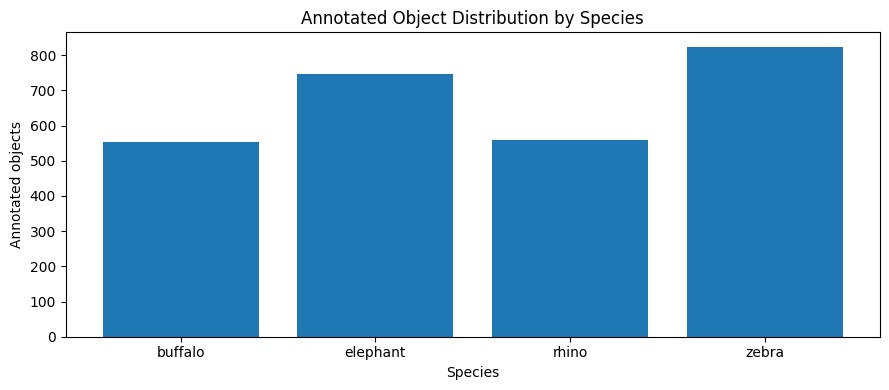

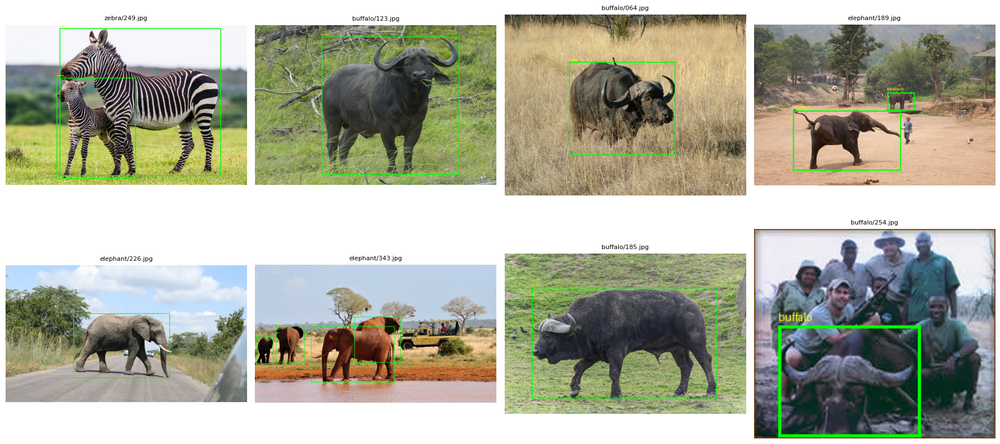

In [ ]:
plt.figure(figsize=(9, 4))

plt.bar(
    class_distribution_df["species"],
    class_distribution_df["objects"]
)

plt.title("Annotated Object Distribution by Species")
plt.xlabel("Species")
plt.ylabel("Annotated objects")

plt.tight_layout()
plt.show()


def draw_ground_truth(image_path, label_path):

    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)

    width, height = image.size

    for line in label_path.read_text().splitlines():

        values = line.split()

        if len(values) != 5:
            continue

        class_id, xc, yc, bw, bh = map(float, values)

        x1 = (xc - bw/2) * width
        y1 = (yc - bh/2) * height

        x2 = (xc + bw/2) * width
        y2 = (yc + bh/2) * height

        draw.rectangle(
            (x1, y1, x2, y2),
            outline="lime",
            width=3
        )

        draw.text(
            (x1, max(0, y1-15)),
            CLASS_NAMES[int(class_id)],
            fill="yellow"
        )

    return image


sample_rows = random.sample(
    pair_rows,
    min(8, len(pair_rows))
)

fig, axes = plt.subplots(
    2, 4,
    figsize=(18, 9)
)

axes = axes.flatten()

for ax, row in zip(axes, sample_rows):

    ax.imshow(
        draw_ground_truth(
            row["image_path"],
            row["label_path"]
        )
    )

    ax.set_title(
        f'{row["folder"]}/{row["image_path"].name}',
        fontsize=8
    )

    ax.axis("off")

for ax in axes[len(sample_rows):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
if CLEAN_DIR.exists():
    shutil.rmtree(CLEAN_DIR)

CLEAN_DIR.mkdir(parents=True, exist_ok=True)

clean_pairs = []

for row in pair_rows:

    destination = CLEAN_DIR / row["folder"]
    destination.mkdir(parents=True, exist_ok=True)

    image_destination = destination / row["image_path"].name
    label_destination = destination / row["label_path"].name

    shutil.copy2(
        row["image_path"],
        image_destination
    )

    shutil.copy2(
        row["label_path"],
        label_destination
    )

    clean_pairs.append({
        "folder": row["folder"],
        "image_path": image_destination,
        "label_path": label_destination
    })

print("Clean image-label pairs:", len(clean_pairs))
print("Clean dataset:", CLEAN_DIR)

Clean image-label pairs: 1504
Clean dataset: /content/wildlife_smart_monitoring/dataset_clean


In [ ]:
indices = np.arange(len(clean_pairs))
groups = [row["folder"] for row in clean_pairs]

train_indices, temporary_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=groups
)

temporary_groups = [
    groups[i] for i in temporary_indices
]

val_indices, test_indices = train_test_split(
    temporary_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=temporary_groups
)

split_indices = {
    "train": train_indices,
    "val": val_indices,
    "test": test_indices
}

if YOLO_DATASET_DIR.exists():
    shutil.rmtree(YOLO_DATASET_DIR)

for split_name in split_indices:

    (YOLO_DATASET_DIR / "images" / split_name).mkdir(
        parents=True,
        exist_ok=True
    )

    (YOLO_DATASET_DIR / "labels" / split_name).mkdir(
        parents=True,
        exist_ok=True
    )

split_report = []

for split_name, split_ids in split_indices.items():

    for index in split_ids:

        row = clean_pairs[int(index)]

        stem = (
            f'{row["folder"]}_{row["image_path"].stem}'
        )

        shutil.copy2(
            row["image_path"],
            YOLO_DATASET_DIR / "images" / split_name /
            f'{stem}{row["image_path"].suffix.lower()}'
        )

        shutil.copy2(
            row["label_path"],
            YOLO_DATASET_DIR / "labels" / split_name /
            f"{stem}.txt"
        )

    image_count = len(
        list(
            (YOLO_DATASET_DIR / "images" / split_name).iterdir()
        )
    )

    label_count = len(
        list(
            (YOLO_DATASET_DIR / "labels" / split_name).glob("*.txt")
        )
    )

    assert image_count == label_count

    split_report.append({
        "split": split_name,
        "images": image_count,
        "labels": label_count
    })

display(pd.DataFrame(split_report))

print(
    "Total images:",
    sum(row["images"] for row in split_report)
)

,split,images,labels
0,train,1203,1203
1,val,150,150
2,test,151,151


Total images: 1504


In [ ]:
DATA_YAML = YOLO_DATASET_DIR / "data.yaml"

data_config = {
    "path": str(YOLO_DATASET_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": [
        CLASS_NAMES[i]
        for i in range(len(CLASS_NAMES))
    ]
}

DATA_YAML.write_text(
    yaml.safe_dump(data_config, sort_keys=False),
    encoding="utf-8"
)

split_object_rows = []

for split_name in ["train", "val", "test"]:

    counts = Counter()

    for label_path in (
        YOLO_DATASET_DIR / "labels" / split_name
    ).glob("*.txt"):

        for line in label_path.read_text().splitlines():

            values = line.split()

            if len(values) == 5:
                counts[
                    CLASS_NAMES[int(float(values[0]))]
                ] += 1

    for species in CLASS_NAMES.values():

        split_object_rows.append({
            "split": split_name,
            "species": species,
            "objects": counts[species]
        })

display(
    pd.DataFrame(split_object_rows).pivot(
        index="species",
        columns="split",
        values="objects"
    )
)

print("YAML:", DATA_YAML)
print(yaml.safe_load(DATA_YAML.read_text()))

split,test,train,val
species,,,
buffalo,59,433,62
elephant,66,613,69
rhino,67,432,60
zebra,82,651,91


YAML: /content/wildlife_smart_monitoring/yolo_dataset/data.yaml
{'path': '/content/wildlife_smart_monitoring/yolo_dataset', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'names': ['buffalo', 'elephant', 'rhino', 'zebra']}


In [ ]:
base_model = YOLO(MODEL_NAME)

training_run_dir = increment_path(
    RUNS_DIR / "wildlife_yolo11s",
    exist_ok=False
)

base_model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    patience=PATIENCE,
    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,
    device=DEVICE,
    workers=2,
    project=str(RUNS_DIR),
    name=training_run_dir.name,
    exist_ok=False,
    pretrained=True,
    plots=True,
    save=True,
    verbose=True
)

BEST_MODEL_PATH = (
    training_run_dir / "weights" / "best.pt"
)

LAST_MODEL_PATH = (
    training_run_dir / "weights" / "last.pt"
)

if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Best model not found: {BEST_MODEL_PATH}"
    )

print("Best model:", BEST_MODEL_PATH)
print("Last model:", LAST_MODEL_PATH)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/wildlife_smart_monitoring/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=wildlife_yolo11s, nbs=64, nm

In [ ]:
model = YOLO(str(BEST_MODEL_PATH))

print("Loaded:", BEST_MODEL_PATH)
print("Task:", model.task)
print("Classes:", model.names)

expected_names = {
    i: name for i, name in CLASS_NAMES.items()
}

assert model.names == expected_names, (
    f"Class mismatch: {model.names}"
)

print("Class mapping verified.")

Loaded: /content/wildlife_smart_monitoring/runs/wildlife_yolo11s/weights/best.pt
Task: detect
Classes: {0: 'buffalo', 1: 'elephant', 2: 'rhino', 3: 'zebra'}
Class mapping verified.


In [ ]:
test_metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True,
    project=str(RUNS_DIR),
    name="wildlife_test_evaluation",
    exist_ok=True
)

metrics_summary = {
    "precision": float(test_metrics.box.mp),
    "recall": float(test_metrics.box.mr),
    "mAP50": float(test_metrics.box.map50),
    "mAP50-95": float(test_metrics.box.map)
}

metrics_path = (
    MONITORING_DIR / "test_metrics.json"
)

metrics_path.write_text(
    json.dumps(metrics_summary, indent=4)
)

display(
    pd.DataFrame(
        [metrics_summary]
    )
)

print("Saved metrics:", metrics_path)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 75.4±52.1 MB/s, size: 531.9 KB)
val: Scanning /content/wildlife_smart_monitoring/yolo_dataset/labels/test... 151 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 151/151 472.9it/s 0.3s
val: /content/wildlife_smart_monitoring/yolo_dataset/images/test/buffalo_054.jpg: corrupt JPEG restored and saved
val: /content/wildlife_smart_monitoring/yolo_dataset/images/test/rhino_037.jpg: corrupt JPEG restored and saved
val: New cache created: /content/wildlife_smart_monitoring/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.0it/s 3.3s
                   all        151        274      0.966      0.882      0.935      0.807
               buffalo         38         59      0.979      0

,precision,recall,mAP50,mAP50-95
0,0.965692,0.882245,0.935461,0.806604


Saved metrics: /content/wildlife_smart_monitoring/monitoring_outputs/test_metrics.json


Results saved to /content/wildlife_smart_monitoring/runs/wildlife_test_predictions


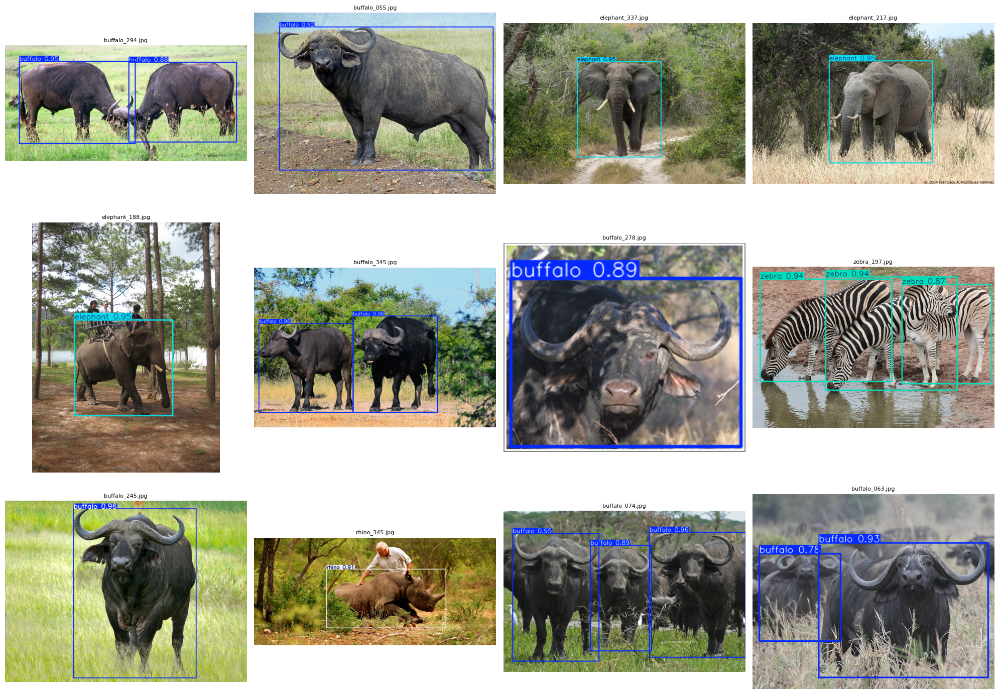

Images visualized: 12


In [ ]:
TEST_IMAGE_DIR = YOLO_DATASET_DIR / "images" / "test"

test_image_paths = sorted([
    p for p in TEST_IMAGE_DIR.iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
])

if not test_image_paths:
    raise RuntimeError("No test images found.")

random.seed(SEED)

selected_test_images = random.sample(
    test_image_paths,
    min(12, len(test_image_paths))
)

prediction_results = model.predict(
    source=[str(p) for p in selected_test_images],
    imgsz=IMAGE_SIZE,
    conf=CONFIDENCE_THRESHOLD,
    iou=NMS_IOU_THRESHOLD,
    device=DEVICE,
    save=True,
    project=str(RUNS_DIR),
    name="wildlife_test_predictions",
    exist_ok=False,
    verbose=False
)

columns = 4
rows = math.ceil(len(prediction_results) / columns)

fig, axes = plt.subplots(
    rows, columns,
    figsize=(20, rows * 5)
)

axes = np.array(axes).reshape(-1)

for index, result in enumerate(prediction_results):

    annotated = cv2.cvtColor(
        result.plot(),
        cv2.COLOR_BGR2RGB
    )

    axes[index].imshow(annotated)
    axes[index].set_title(
        selected_test_images[index].name,
        fontsize=8
    )
    axes[index].axis("off")

for ax in axes[len(prediction_results):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Images visualized:", len(prediction_results))

In [ ]:
def calculate_iou_xyxy(box_a, box_b):

    x_left = max(box_a[0], box_b[0])
    y_top = max(box_a[1], box_b[1])

    x_right = min(box_a[2], box_b[2])
    y_bottom = min(box_a[3], box_b[3])

    intersection = (
        max(0, x_right-x_left)
        * max(0, y_bottom-y_top)
    )

    area_a = (
        max(0, box_a[2]-box_a[0])
        * max(0, box_a[3]-box_a[1])
    )

    area_b = (
        max(0, box_b[2]-box_b[0])
        * max(0, box_b[3]-box_b[1])
    )

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


def read_yolo_ground_truth(
    label_path,
    image_width,
    image_height
):

    ground_truth = []

    for line in label_path.read_text().splitlines():

        values = line.split()

        if len(values) != 5:
            continue

        class_id, xc, yc, bw, bh = map(float, values)

        ground_truth.append({
            "class_id": int(class_id),
            "box": [
                (xc-bw/2)*image_width,
                (yc-bh/2)*image_height,
                (xc+bw/2)*image_width,
                (yc+bh/2)*image_height
            ]
        })

    return ground_truth


error_stats = {
    i: {"TP": 0, "FP": 0, "FN": 0}
    for i in CLASS_NAMES
}

error_image_rows = []

ERROR_IMAGE_DIR = MONITORING_DIR / "error_examples"
ERROR_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

for old_file in ERROR_IMAGE_DIR.iterdir():

    if old_file.is_file():
        old_file.unlink()


for image_path in test_image_paths:

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    height, width = image.shape[:2]

    label_path = (
        YOLO_DATASET_DIR
        / "labels"
        / "test"
        / f"{image_path.stem}.txt"
    )

    ground_truth = read_yolo_ground_truth(
        label_path,
        width,
        height
    )

    result = model.predict(
        source=str(image_path),
        imgsz=IMAGE_SIZE,
        conf=CONFIDENCE_THRESHOLD,
        iou=NMS_IOU_THRESHOLD,
        device=DEVICE,
        verbose=False
    )[0]

    predictions = []

    if result.boxes is not None:

        for box in result.boxes:

            predictions.append({
                "class_id": int(box.cls.item()),
                "confidence": float(box.conf.item()),
                "box": box.xyxy[0].cpu().tolist()
            })

    predictions.sort(
        key=lambda item: item["confidence"],
        reverse=True
    )

    matched_gt = set()
    matched_predictions = set()

    for pred_index, prediction in enumerate(predictions):

        best_iou = 0.0
        best_gt_index = None

        for gt_index, gt in enumerate(ground_truth):

            if (
                gt_index in matched_gt
                or prediction["class_id"] != gt["class_id"]
            ):
                continue

            overlap = calculate_iou_xyxy(
                prediction["box"],
                gt["box"]
            )

            if overlap > best_iou:
                best_iou = overlap
                best_gt_index = gt_index

        if (
            best_gt_index is not None
            and best_iou >= MATCH_IOU_THRESHOLD
        ):

            matched_gt.add(best_gt_index)
            matched_predictions.add(pred_index)

            error_stats[
                prediction["class_id"]
            ]["TP"] += 1

    for i, prediction in enumerate(predictions):

        if i not in matched_predictions:

            error_stats[
                prediction["class_id"]
            ]["FP"] += 1

    for i, gt in enumerate(ground_truth):

        if i not in matched_gt:

            error_stats[
                gt["class_id"]
            ]["FN"] += 1

    fp_count = (
        len(predictions) - len(matched_predictions)
    )

    fn_count = (
        len(ground_truth) - len(matched_gt)
    )

    error_image_rows.append({
        "image": image_path.name,
        "ground_truth": len(ground_truth),
        "predictions": len(predictions),
        "TP": len(matched_predictions),
        "FP": fp_count,
        "FN": fn_count
    })

    if fp_count > 0 or fn_count > 0:

        annotated = image.copy()

        # Ground truth boxes: green
        for gt in ground_truth:

            x1, y1, x2, y2 = map(
                int,
                gt["box"]
            )

            cv2.rectangle(
                annotated,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            cv2.putText(
                annotated,
                f'GT: {CLASS_NAMES[gt["class_id"]]}',
                (x1, max(18, y1-5)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 0),
                2
            )

        # Predictions: red
        for pred in predictions:

            x1, y1, x2, y2 = map(
                int,
                pred["box"]
            )

            cv2.rectangle(
                annotated,
                (x1, y1),
                (x2, y2),
                (0, 0, 255),
                2
            )

            cv2.putText(
                annotated,
                f'PRED: {CLASS_NAMES[pred["class_id"]]} '
                f'{pred["confidence"]:.2f}',
                (x1, min(height-5, y2+16)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45,
                (0, 0, 255),
                2
            )

        cv2.imwrite(
            str(ERROR_IMAGE_DIR / image_path.name),
            annotated
        )


error_summary_rows = []

for class_id, stats in error_stats.items():

    tp = stats["TP"]
    fp = stats["FP"]
    fn = stats["FN"]

    error_summary_rows.append({
        "species": CLASS_NAMES[class_id],
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision_at_threshold": (
            tp/(tp+fp) if tp+fp else 0.0
        ),
        "recall_at_threshold": (
            tp/(tp+fn) if tp+fn else 0.0
        )
    })


error_summary_df = pd.DataFrame(error_summary_rows)
error_images_df = pd.DataFrame(error_image_rows)

display(error_summary_df)

error_summary_df.to_csv(
    MONITORING_DIR / "detection_error_summary.csv",
    index=False
)

error_images_df.to_csv(
    MONITORING_DIR / "per_image_error_report.csv",
    index=False
)

print(
    "Error example images:",
    len(list(ERROR_IMAGE_DIR.iterdir()))
)

,species,TP,FP,FN,precision_at_threshold,recall_at_threshold
0,buffalo,49,2,10,0.960784,0.830508
1,elephant,60,7,6,0.895522,0.909091
2,rhino,65,2,2,0.970149,0.970149
3,zebra,77,14,5,0.846154,0.939024


Error example images: 26


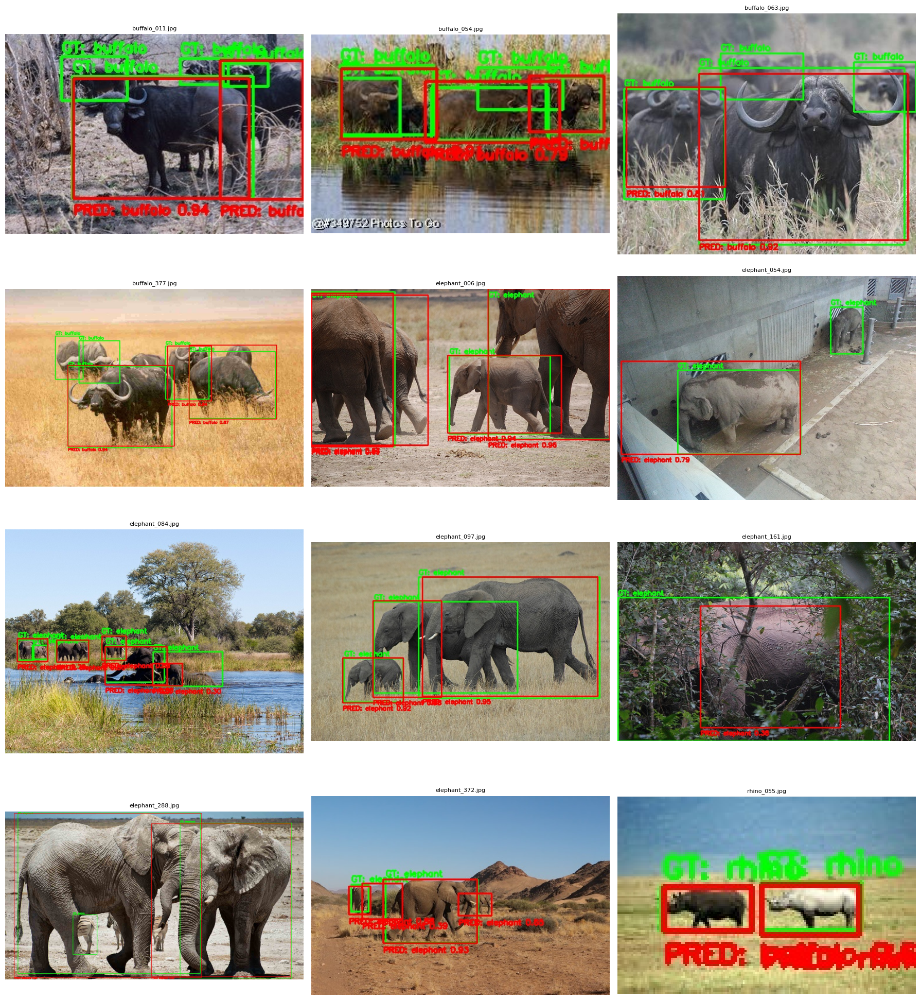

In [ ]:
error_image_paths = sorted([
    p for p in ERROR_IMAGE_DIR.iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
])

if not error_image_paths:

    print("No FP/FN examples at the selected thresholds.")

else:

    selected_errors = error_image_paths[:12]

    columns = 3
    rows = math.ceil(
        len(selected_errors) / columns
    )

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(18, rows*5)
    )

    axes = np.array(axes).reshape(-1)

    for ax, path in zip(axes, selected_errors):

        image = cv2.cvtColor(
            cv2.imread(str(path)),
            cv2.COLOR_BGR2RGB
        )

        ax.imshow(image)
        ax.set_title(path.name, fontsize=8)
        ax.axis("off")

    for ax in axes[len(selected_errors):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
# CELL 15 — Generate a demonstration wildlife video
import cv2
import numpy as np
import random

VIDEO_PATH = str(MONITORING_DIR / "simulated_wildlife.mp4")

# Use existing test images
video_images = selected_test_images[:12]

if not video_images:
    raise RuntimeError("No test images available.")

VIDEO_FPS = 10
VIDEO_WIDTH = 640
VIDEO_HEIGHT = 640
SECONDS_PER_IMAGE = 3

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

video_writer = cv2.VideoWriter(
    VIDEO_PATH,
    fourcc,
    VIDEO_FPS,
    (VIDEO_WIDTH, VIDEO_HEIGHT)
)

if not video_writer.isOpened():
    raise RuntimeError("Could not create MP4 video.")

for image_path in video_images:

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    # Resize while maintaining aspect ratio
    h, w = image.shape[:2]
    scale = min(VIDEO_WIDTH / w, VIDEO_HEIGHT / h)

    new_w = int(w * scale)
    new_h = int(h * scale)

    resized = cv2.resize(image, (new_w, new_h))

    frame = np.zeros(
        (VIDEO_HEIGHT, VIDEO_WIDTH, 3),
        dtype=np.uint8
    )

    x_offset = (VIDEO_WIDTH - new_w) // 2
    y_offset = (VIDEO_HEIGHT - new_h) // 2

    frame[
        y_offset:y_offset + new_h,
        x_offset:x_offset + new_w
    ] = resized

    # Hold each image for three seconds
    for _ in range(VIDEO_FPS * SECONDS_PER_IMAGE):
        video_writer.write(frame)

video_writer.release()

# Read video metadata
video_capture = cv2.VideoCapture(VIDEO_PATH)

if not video_capture.isOpened():
    raise RuntimeError("Generated video could not be opened.")

VIDEO_FPS = video_capture.get(cv2.CAP_PROP_FPS)
VIDEO_WIDTH = int(video_capture.get(cv2.CAP_PROP_FRAME_WIDTH))
VIDEO_HEIGHT = int(video_capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
VIDEO_FRAME_COUNT = int(video_capture.get(cv2.CAP_PROP_FRAME_COUNT))

video_capture.release()

print("Generated video:", VIDEO_PATH)
print("FPS:", VIDEO_FPS)
print("Resolution:", VIDEO_WIDTH, "x", VIDEO_HEIGHT)
print("Total frames:", VIDEO_FRAME_COUNT)
print("Duration:", VIDEO_FRAME_COUNT / VIDEO_FPS, "seconds")

Generated video: /content/wildlife_smart_monitoring/monitoring_outputs/simulated_wildlife.mp4
FPS: 10.0
Resolution: 640 x 640
Total frames: 360
Duration: 36.0 seconds


In [ ]:
VIDEO_PATH = str(MONITORING_DIR / "simulated_wildlife.mp4")

In [ ]:
TRACKED_VIDEO_PATH = (
    MONITORING_DIR / "tracked_wildlife.mp4"
)

TRACKING_HISTORY_PATH = (
    MONITORING_DIR / "tracking_history.csv"
)

EVENTS_PATH = (
    MONITORING_DIR / "wildlife_events.csv"
)


# Protected-zone coordinates
zone_x1 = int(
    PROTECTED_ZONE_FRACTION[0] * VIDEO_WIDTH
)

zone_y1 = int(
    PROTECTED_ZONE_FRACTION[1] * VIDEO_HEIGHT
)

zone_x2 = int(
    PROTECTED_ZONE_FRACTION[2] * VIDEO_WIDTH
)

zone_y2 = int(
    PROTECTED_ZONE_FRACTION[3] * VIDEO_HEIGHT
)

# Horizontal virtual line
line_y = VIDEO_HEIGHT // 2

if not (
    0 <= zone_x1 < zone_x2 <= VIDEO_WIDTH
    and 0 <= zone_y1 < zone_y2 <= VIDEO_HEIGHT
):
    raise ValueError(
        "Invalid protected-zone coordinates."
    )


video_writer = cv2.VideoWriter(
    str(TRACKED_VIDEO_PATH),
    cv2.VideoWriter_fourcc(*"mp4v"),
    VIDEO_FPS,
    (VIDEO_WIDTH, VIDEO_HEIGHT)
)

if not video_writer.isOpened():
    raise RuntimeError(
        "Could not initialize output video writer."
    )


unique_tracks = defaultdict(set)

previous_centers = {}
previous_zone_state = {}

crossed_tracks = set()
zone_entry_tracks = set()

history_rows = []
event_rows = []

frame_number = 0


tracking_stream = model.track(
    source=VIDEO_PATH,
    tracker=TRACKER_CONFIG,
    conf=VIDEO_CONFIDENCE,
    iou=NMS_IOU_THRESHOLD,
    imgsz=IMAGE_SIZE,
    persist=True,
    stream=True,
    device=DEVICE,
    verbose=False
)


for result in tracking_stream:

    frame_number += 1

    frame = result.orig_img.copy()

    # Draw virtual line
    cv2.line(
        frame,
        (0, line_y),
        (VIDEO_WIDTH, line_y),
        (255, 255, 0),
        2
    )

    # Draw protected zone
    cv2.rectangle(
        frame,
        (zone_x1, zone_y1),
        (zone_x2, zone_y2),
        (0, 165, 255),
        2
    )

    cv2.putText(
        frame,
        "PROTECTED MONITORING ZONE",
        (zone_x1, max(20, zone_y1-8)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        (0, 165, 255),
        2
    )

    boxes = result.boxes

    if (
        boxes is not None
        and boxes.id is not None
        and len(boxes) > 0
    ):

        track_ids = boxes.id.int().cpu().tolist()

        class_ids = boxes.cls.int().cpu().tolist()

        confidences = boxes.conf.cpu().tolist()

        coordinates = boxes.xyxy.cpu().numpy()


        for (
            track_id,
            class_id,
            confidence,
            box
        ) in zip(
            track_ids,
            class_ids,
            confidences,
            coordinates
        ):

            if class_id not in CLASS_NAMES:
                continue

            x1, y1, x2, y2 = map(int, box)

            center_x = (x1+x2)//2
            center_y = (y1+y2)//2

            species = CLASS_NAMES[class_id]

            track_key = (
                class_id,
                int(track_id)
            )

            unique_tracks[species].add(
                int(track_id)
            )


            # ---------------------------------
            # VIRTUAL LINE CROSSING DETECTION
            # ---------------------------------

            if track_key in previous_centers:

                previous_y = (
                    previous_centers[track_key][1]
                )

                crossed = (
                    (previous_y < line_y <= center_y)
                    or
                    (previous_y > line_y >= center_y)
                )

                if (
                    crossed
                    and track_key not in crossed_tracks
                ):

                    crossed_tracks.add(track_key)

                    event_rows.append({
                        "frame": frame_number,
                        "time_seconds": round(
                            frame_number/VIDEO_FPS, 3
                        ),
                        "track_id": int(track_id),
                        "species": species,
                        "event": "LINE_CROSSING",
                        "priority": "INFO"
                    })

            previous_centers[track_key] = (
                center_x,
                center_y
            )


            # ---------------------------------
            # PROTECTED ZONE ENTRY DETECTION
            # ---------------------------------

            inside_zone = (
                zone_x1 <= center_x <= zone_x2
                and
                zone_y1 <= center_y <= zone_y2
            )

            was_inside = previous_zone_state.get(
                track_key,
                False
            )

            if (
                inside_zone
                and not was_inside
                and track_key not in zone_entry_tracks
            ):

                zone_entry_tracks.add(track_key)

                priority = {
                    "elephant": "HIGH",
                    "rhino": "MEDIUM",
                    "buffalo": "MEDIUM",
                    "zebra": "LOW"
                }[species]

                event_rows.append({
                    "frame": frame_number,
                    "time_seconds": round(
                        frame_number/VIDEO_FPS, 3
                    ),
                    "track_id": int(track_id),
                    "species": species,
                    "event": "PROTECTED_ZONE_ENTRY",
                    "priority": priority
                })

            previous_zone_state[track_key] = (
                inside_zone
            )


            # ---------------------------------
            # DRAW TRACKING BOXES
            # ---------------------------------

            cv2.rectangle(
                frame,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            cv2.putText(
                frame,
                f"{species} | ID {track_id} | {confidence:.2f}",
                (x1, max(20, y1-7)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 255, 0),
                2
            )


    # ---------------------------------
    # SAVE PER-FRAME COUNT HISTORY
    # ---------------------------------

    for species in CLASS_NAMES.values():

        history_rows.append({
            "frame": frame_number,
            "time_seconds": round(
                frame_number/VIDEO_FPS, 3
            ),
            "species": species,
            "cumulative_unique_tracks": len(
                unique_tracks[species]
            )
        })


    video_writer.write(frame)


video_writer.release()


# Save tracking history
tracking_history_df = pd.DataFrame(
    history_rows
)

events_df = pd.DataFrame(
    event_rows,
    columns=[
        "frame",
        "time_seconds",
        "track_id",
        "species",
        "event",
        "priority"
    ]
)

tracking_history_df.to_csv(
    TRACKING_HISTORY_PATH,
    index=False
)

events_df.to_csv(
    EVENTS_PATH,
    index=False
)


unique_track_summary = pd.DataFrame([
    {
        "species": species,
        "unique_track_ids": len(
            unique_tracks[species]
        )
    }
    for species in CLASS_NAMES.values()
])

print("Tracking complete. Frames:", frame_number)
print("Annotated video:", TRACKED_VIDEO_PATH)

display(unique_track_summary)
display(events_df.head(20))

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 191ms
Prepared 1 package in 48ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Tracking complete. Frames: 360
Annotated video: /content/wildlife_smart_monitoring/monitoring_outputs/tracked_wildlife.mp4


,species,unique_track_ids
0,buffalo,6
1,elephant,1
2,rhino,1
3,zebra,3


,frame,time_seconds,track_id,species,event,priority
0,1,0.1,2,buffalo,PROTECTED_ZONE_ENTRY,MEDIUM
1,151,15.1,1,buffalo,LINE_CROSSING,INFO
2,212,21.2,5,zebra,PROTECTED_ZONE_ENTRY,LOW
3,302,30.2,6,buffalo,PROTECTED_ZONE_ENTRY,MEDIUM


Unique track IDs observed by species:


,unique_track_ids
species,
buffalo,6
elephant,1
rhino,1
zebra,3


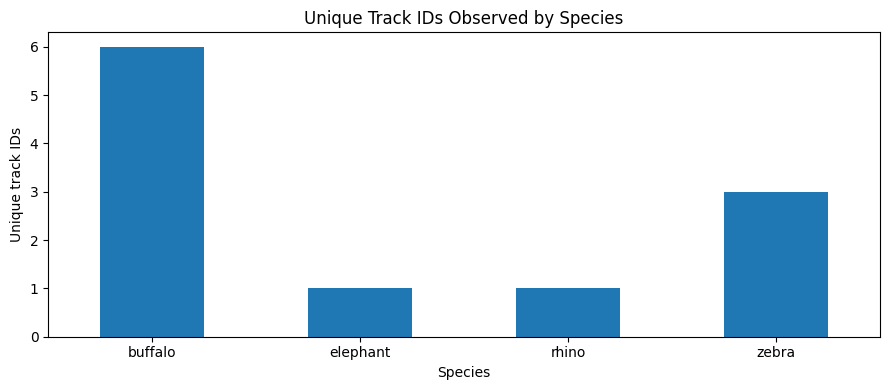

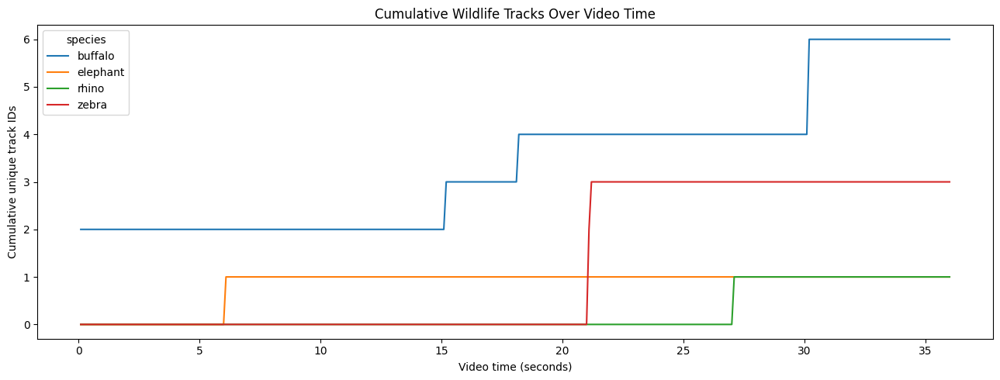

,event_count
event,
PROTECTED_ZONE_ENTRY,3
LINE_CROSSING,1


,event_count
priority,
MEDIUM,2
INFO,1
LOW,1


In [ ]:
if tracking_history_df.empty:
    raise RuntimeError(
        "Tracking history is empty."
    )


species_summary = (
    tracking_history_df
    .groupby("species")["cumulative_unique_tracks"]
    .max()
    .reindex(
        list(CLASS_NAMES.values()),
        fill_value=0
    )
)

print("Unique track IDs observed by species:")

display(
    species_summary.rename(
        "unique_track_ids"
    ).to_frame()
)


# Chart 1: Unique track IDs per species
fig, ax = plt.subplots(figsize=(9, 4))

species_summary.plot(
    kind="bar",
    ax=ax
)

ax.set_title(
    "Unique Track IDs Observed by Species"
)

ax.set_xlabel("Species")
ax.set_ylabel("Unique track IDs")

ax.tick_params(
    axis="x",
    rotation=0
)

plt.tight_layout()
plt.show()


# Chart 2: Wildlife activity over time
activity_pivot = tracking_history_df.pivot(
    index="time_seconds",
    columns="species",
    values="cumulative_unique_tracks"
).ffill()

fig, ax = plt.subplots(figsize=(13, 5))

activity_pivot.plot(ax=ax)

ax.set_title(
    "Cumulative Wildlife Tracks Over Video Time"
)

ax.set_xlabel("Video time (seconds)")
ax.set_ylabel("Cumulative unique track IDs")

plt.tight_layout()
plt.show()


# Event summaries
if events_df.empty:

    print(
        "No line-crossing or protected-zone "
        "entry events were recorded."
    )

else:

    display(
        events_df["event"]
        .value_counts()
        .rename("event_count")
        .to_frame()
    )

    display(
        events_df["priority"]
        .value_counts()
        .rename("event_count")
        .to_frame()
    )

In [ ]:
def assign_monitoring_score(row):

    if row["event"] == "LINE_CROSSING":

        return pd.Series({
            "risk_score": 0,
            "risk_label": "INFO"
        })

    rules = {
        "elephant": (3, "HIGH"),
        "rhino": (2, "MEDIUM"),
        "buffalo": (2, "MEDIUM"),
        "zebra": (1, "LOW")
    }

    score, label = rules.get(
        row["species"],
        (0, "INFO")
    )

    return pd.Series({
        "risk_score": score,
        "risk_label": label
    })


if events_df.empty:

    threat_analysis_df = pd.DataFrame(
        columns=[
            "frame",
            "time_seconds",
            "track_id",
            "species",
            "event",
            "priority",
            "risk_score",
            "risk_label"
        ]
    )

else:

    threat_analysis_df = events_df.copy()

    threat_analysis_df[
        ["risk_score", "risk_label"]
    ] = threat_analysis_df.apply(
        assign_monitoring_score,
        axis=1
    )


THREAT_REPORT_PATH = (
    MONITORING_DIR / "threat_analysis.csv"
)

threat_analysis_df.to_csv(
    THREAT_REPORT_PATH,
    index=False
)


if threat_analysis_df.empty:

    print("No events to analyze.")

else:

    display(threat_analysis_df)

    display(
        threat_analysis_df
        .groupby(["event", "risk_label"])
        .size()
        .rename("event_count")
        .reset_index()
    )

print("Saved:", THREAT_REPORT_PATH)

,frame,time_seconds,track_id,species,event,priority,risk_score,risk_label
0,1,0.1,2,buffalo,PROTECTED_ZONE_ENTRY,MEDIUM,2,MEDIUM
1,151,15.1,1,buffalo,LINE_CROSSING,INFO,0,INFO
2,212,21.2,5,zebra,PROTECTED_ZONE_ENTRY,LOW,1,LOW
3,302,30.2,6,buffalo,PROTECTED_ZONE_ENTRY,MEDIUM,2,MEDIUM


,event,risk_label,event_count
0,LINE_CROSSING,INFO,1
1,PROTECTED_ZONE_ENTRY,LOW,1
2,PROTECTED_ZONE_ENTRY,MEDIUM,2


Saved: /content/wildlife_smart_monitoring/monitoring_outputs/threat_analysis.csv


VIDEO PATH: /content/wildlife_smart_monitoring/monitoring_outputs/tracked_wildlife.mp4
FILE EXISTS: True
FILE SIZE: 5308.7 KB
VIDEO OPENED: True
FPS: 10.0
FRAME COUNT: 360
FIRST FRAME READABLE: True
FRAME SHAPE: (640, 640, 3)


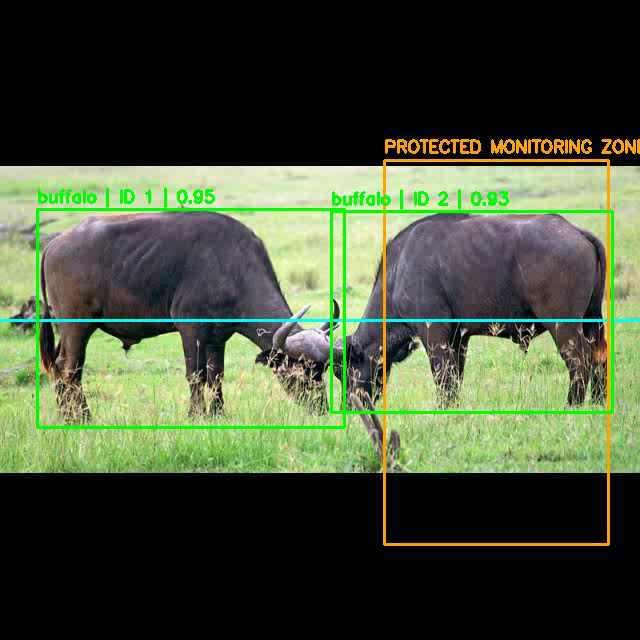

In [ ]:
# Diagnose annotated video

print("VIDEO PATH:", TRACKED_VIDEO_PATH)
print("FILE EXISTS:", TRACKED_VIDEO_PATH.exists())

if TRACKED_VIDEO_PATH.exists():

    print(
        "FILE SIZE:",
        round(TRACKED_VIDEO_PATH.stat().st_size / 1024, 2),
        "KB"
    )

    cap = cv2.VideoCapture(str(TRACKED_VIDEO_PATH))

    print("VIDEO OPENED:", cap.isOpened())
    print("FPS:", cap.get(cv2.CAP_PROP_FPS))
    print("FRAME COUNT:", int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    ))

    success, frame = cap.read()

    print("FIRST FRAME READABLE:", success)

    if success:
        print("FRAME SHAPE:", frame.shape)
        display(
            Image.fromarray(
                cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            )
        )

    cap.release()

else:
    print("Annotated video was not generated.")

In [ ]:
import subprocess

BROWSER_VIDEO_PATH = str(
    MONITORING_DIR / "tracked_wildlife_browser.mp4"
)

subprocess.run([
    "ffmpeg",
    "-y",
    "-i", str(TRACKED_VIDEO_PATH),
    "-vcodec", "libx264",
    "-pix_fmt", "yuv420p",
    "-movflags", "+faststart",
    "-an",
    BROWSER_VIDEO_PATH
], check=True)

print("Converted video:", BROWSER_VIDEO_PATH)

Converted video: /content/wildlife_smart_monitoring/monitoring_outputs/tracked_wildlife_browser.mp4


In [ ]:
display(
    Video(
        BROWSER_VIDEO_PATH,
        embed=True,
        width=800
    )
)

In [ ]:
APP_SOURCE = r"""
from pathlib import Path
import json
import pandas as pd
import streamlit as st
import plotly.express as px

BASE_DIR = Path(__file__).resolve().parent
REPORT_DIR = BASE_DIR / "monitoring_outputs"

st.set_page_config(
    page_title="Smart Wildlife Monitoring",
    page_icon="🐘",
    layout="wide"
)

st.title("Smart Wildlife Monitoring and Threat Analysis")

st.caption(
    "YOLO11s detection | ByteTrack tracking | "
    "Protected-zone monitoring"
)


def load_json(path):
    return json.loads(path.read_text()) if path.exists() else {}


# Load model metrics
metrics = load_json(
    REPORT_DIR / "test_metrics.json"
)

# Load tracking and event reports
history_path = REPORT_DIR / "tracking_history.csv"
events_path = REPORT_DIR / "wildlife_events.csv"
threat_path = REPORT_DIR / "threat_analysis.csv"
video_path = REPORT_DIR / "tracked_wildlife.mp4"

history = (
    pd.read_csv(history_path)
    if history_path.exists()
    else pd.DataFrame()
)

events = (
    pd.read_csv(events_path)
    if events_path.exists()
    else pd.DataFrame()
)

threats = (
    pd.read_csv(threat_path)
    if threat_path.exists()
    else pd.DataFrame()
)


# MODEL PERFORMANCE
st.subheader("Detection model performance")

c1, c2, c3, c4 = st.columns(4)

c1.metric(
    "Precision",
    f"{metrics.get('precision', 0):.3f}"
)

c2.metric(
    "Recall",
    f"{metrics.get('recall', 0):.3f}"
)

c3.metric(
    "mAP@50",
    f"{metrics.get('mAP50', 0):.3f}"
)

c4.metric(
    "mAP@50-95",
    f"{metrics.get('mAP50-95', 0):.3f}"
)


st.divider()


# VIDEO AND UNIQUE TRACKS
left, right = st.columns([1.4, 1])

with left:

    st.subheader("Tracked wildlife video")

    if video_path.exists():
        st.video(str(video_path))

    else:
        st.info(
            "Run the notebook tracking cells to create a video."
        )


with right:

    st.subheader("Unique track IDs by species")

    if not history.empty:

        summary = (
            history
            .groupby("species")[
                "cumulative_unique_tracks"
            ]
            .max()
            .reset_index()
        )

        summary.columns = [
            "species",
            "unique_track_ids"
        ]

        st.plotly_chart(
            px.bar(
                summary,
                x="species",
                y="unique_track_ids"
            ),
            use_container_width=True
        )

        st.metric(
            "Total unique track IDs",
            int(summary["unique_track_ids"].sum())
        )

    else:

        st.info("No tracking history available.")


st.divider()


# ACTIVITY GRAPH
st.subheader("Wildlife activity over time")

if not history.empty:

    st.plotly_chart(
        px.line(
            history,
            x="time_seconds",
            y="cumulative_unique_tracks",
            color="species"
        ),
        use_container_width=True
    )

else:

    st.info("No tracking history available.")


# EVENTS
st.subheader("Monitoring events")

if not events.empty:

    a, b, c = st.columns(3)

    a.metric(
        "Total events",
        len(events)
    )

    b.metric(
        "Line crossings",
        int(
            (events["event"] == "LINE_CROSSING").sum()
        )
    )

    c.metric(
        "Protected-zone entries",
        int(
            (
                events["event"]
                == "PROTECTED_ZONE_ENTRY"
            ).sum()
        )
    )

    st.dataframe(
        events,
        use_container_width=True
    )

else:

    st.info("No events were recorded.")


# THREAT ANALYSIS
st.subheader("Threat and priority analysis")

if not threats.empty:

    if "risk_label" in threats.columns:

        counts = (
            threats["risk_label"]
            .value_counts()
            .reset_index()
        )

        counts.columns = [
            "priority",
            "events"
        ]

        st.plotly_chart(
            px.bar(
                counts,
                x="priority",
                y="events"
            ),
            use_container_width=True
        )

    st.dataframe(
        threats,
        use_container_width=True
    )

else:

    st.info(
        "Threat analysis report is not available."
    )


st.caption(
    "Track IDs are not biological identities. "
    "Zone events and priorities are monitoring aids, "
    "not proof of danger or illegal activity."
)
"""

APP_PATH = PROJECT_ROOT / "app.py"

APP_PATH.write_text(
    APP_SOURCE,
    encoding="utf-8"
)

print("Dashboard app created:", APP_PATH)

Dashboard app created: /content/wildlife_smart_monitoring/app.py


In [ ]:
EXPORT_ONNX = False

if EXPORT_ONNX:

    onnx_path = model.export(
        format="onnx",
        imgsz=IMAGE_SIZE,
        simplify=True
    )

    print("ONNX export:", onnx_path)

else:

    print("ONNX export skipped.")

ONNX export skipped.


In [ ]:
INCLUDE_VIDEO_IN_PACKAGE = False

if FINAL_DIR.exists():
    shutil.rmtree(FINAL_DIR)

FINAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Copy trained model
shutil.copy2(
    BEST_MODEL_PATH,
    FINAL_DIR / "wildlife_yolo11s_best.pt"
)


# Copy dataset configuration
shutil.copy2(
    DATA_YAML,
    FINAL_DIR / "data.yaml"
)


# Save class mapping
(FINAL_DIR / "classes.txt").write_text(
    "\n".join(
        f"{class_id}: {name}"
        for class_id, name in CLASS_NAMES.items()
    ),
    encoding="utf-8"
)


# Copy monitoring reports
final_reports_dir = (
    FINAL_DIR / "monitoring_outputs"
)

final_reports_dir.mkdir(
    parents=True,
    exist_ok=True
)


for report_file in MONITORING_DIR.iterdir():

    if report_file.is_file():

        if (
            report_file.name == "tracked_wildlife.mp4"
            and not INCLUDE_VIDEO_IN_PACKAGE
        ):
            continue

        shutil.copy2(
            report_file,
            final_reports_dir / report_file.name
        )


# Copy dashboard
if APP_PATH.exists():

    shutil.copy2(
        APP_PATH,
        FINAL_DIR / "app.py"
    )


# Dependencies
(FINAL_DIR / "requirements.txt").write_text(
    "ultralytics\n"
    "streamlit\n"
    "plotly\n"
    "pandas\n"
    "opencv-python\n"
    "pyyaml\n",
    encoding="utf-8"
)


# README
readme = f'''
SMART WILDLIFE MONITORING AND THREAT ANALYSIS SYSTEM
====================================================

Detector: YOLO11s
Tracker: ByteTrack
Image size: {IMAGE_SIZE}

CLASSES
-------
0 - buffalo
1 - elephant
2 - rhino
3 - zebra

MODULES
-------
- Four-class wildlife object detection
- Held-out test evaluation
- Threshold-specific TP/FP/FN analysis
- Video-based multi-object tracking
- Unique track ID counting
- Virtual line-crossing events
- Protected-zone entry monitoring
- Rule-based monitoring priorities
- Wildlife activity analytics
- Streamlit dashboard

LIMITATIONS
-----------
Track IDs are not verified biological identities.
Zone entries do not prove danger or illegal activity.
Priority labels are configurable heuristics,
not validated probabilities.

Only the four listed animal classes are detected.

DASHBOARD
---------
pip install -r requirements.txt
streamlit run app.py

The dashboard expects monitoring CSV reports
inside the monitoring_outputs folder.

TEST METRICS
------------
{json.dumps(metrics_summary, indent=2)}
'''

(FINAL_DIR / "README.txt").write_text(
    readme,
    encoding="utf-8"
)


# Create final ZIP
FINAL_ZIP = (
    PROJECT_ROOT / "smart_wildlife_monitoring_system.zip"
)

if FINAL_ZIP.exists():
    FINAL_ZIP.unlink()


with zipfile.ZipFile(
    FINAL_ZIP,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for file_path in FINAL_DIR.rglob("*"):

        if file_path.is_file():

            archive.write(
                file_path,
                arcname=file_path.relative_to(FINAL_DIR)
            )


print("Final package:", FINAL_ZIP)

for file_path in sorted(FINAL_DIR.rglob("*")):

    if file_path.is_file():

        print(
            file_path.relative_to(FINAL_DIR),
            f"{file_path.stat().st_size/(1024*1024):.2f} MB"
        )

Final package: /content/wildlife_smart_monitoring/smart_wildlife_monitoring_system.zip
README.txt 0.00 MB
app.py 0.00 MB
classes.txt 0.00 MB
data.yaml 0.00 MB
monitoring_outputs/detection_error_summary.csv 0.00 MB
monitoring_outputs/per_image_error_report.csv 0.00 MB
monitoring_outputs/simulated_wildlife.mp4 3.20 MB
monitoring_outputs/test_metrics.json 0.00 MB
monitoring_outputs/threat_analysis.csv 0.00 MB
monitoring_outputs/tracked_wildlife_browser.mp4 2.08 MB
monitoring_outputs/tracking_history.csv 0.02 MB
monitoring_outputs/wildlife_events.csv 0.00 MB
requirements.txt 0.00 MB
wildlife_yolo11s_best.pt 18.30 MB


In [ ]:
from google.colab import files

files.download(str(FINAL_ZIP))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/wildlife_smart_monitoring")

for path in PROJECT_ROOT.rglob("app.py"):
    print("APP FOUND:", path)

for path in PROJECT_ROOT.rglob("requirements.txt"):
    print("REQUIREMENTS FOUND:", path)

APP FOUND: /content/wildlife_smart_monitoring/app.py
APP FOUND: /content/wildlife_smart_monitoring/final_package/app.py
REQUIREMENTS FOUND: /content/wildlife_smart_monitoring/final_package/requirements.txt
